Nesta etapa da OAT 3, vamos comparar duas técnicas de otimização de hiperparâmetros para o algoritmo Random Forest: Grid Search e Random Search. O objetivo é avaliar qual método oferece uma relação mais vantajosa entre tempo de processamento e desempenho preditivo na estimativa da demanda diária por trocas de óleo.

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

Nesta etapa, carregamos a base de dados e organizamos os registros em ordem cronológica. Em seguida, criamos três atributos temporais: lag_1, que representa a quantidade de trocas de óleo do dia anterior; lag_7, que representa o valor de sete dias antes; e mm_7, que representa a média dos sete dias anteriores. Esses atributos ajudam o modelo a identificar padrões históricos sem utilizar diretamente valores futuros para construí-los.

In [3]:
df = pd.read_csv(
    "/content/mecaniqa_dataset.csv",
    parse_dates=["Data"]
)

df = df.set_index("Data").sort_index()

df["Trocas_Oleo"] = pd.to_numeric(
    df["Trocas_Oleo"], errors="coerce"
)

df["lag_1"] = df["Trocas_Oleo"].shift(1)
df["lag_7"] = df["Trocas_Oleo"].shift(7)
df["mm_7"] = (
    df["Trocas_Oleo"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

features = ["lag_1", "lag_7", "mm_7"]

df = df.dropna(subset=["Trocas_Oleo"] + features)

X = df[features]
y = df["Trocas_Oleo"]

print("Dimensão da base:", df.shape)
print("Atributos:", features)
print(
    "Período:",
    df.index.min().date(),
    "até",
    df.index.max().date()
)

Dimensão da base: (711, 5)
Atributos: ['lag_1', 'lag_7', 'mm_7']
Período: 2024-01-08 até 2025-12-31


Para avaliar os métodos de forma justa, separamos os dados cronologicamente: os primeiros 80% serão utilizados no treinamento e na busca de hiperparâmetros, enquanto os 20% finais ficarão reservados para a avaliação final. Também utilizamos o TimeSeriesSplit com cinco divisões para realizar a validação temporal sem embaralhar a sequência dos dados.

In [4]:
ponto_corte = int(len(df) * 0.8)

X_treino = X.iloc[:ponto_corte]
X_teste = X.iloc[ponto_corte:]

y_treino = y.iloc[:ponto_corte]
y_teste = y.iloc[ponto_corte:]

print("Treino:", len(X_treino), "registros")
print("Teste:", len(X_teste), "registros")
print("Última data de treino:", X_treino.index.max().date())
print("Primeira data de teste:", X_teste.index.min().date())

tscv = TimeSeriesSplit(n_splits=5)

Treino: 568 registros
Teste: 143 registros
Última data de treino: 2025-08-10
Primeira data de teste: 2025-08-11


Nesta etapa, definimos o espaço de busca dos hiperparâmetros da Random Forest. Serão avaliadas diferentes quantidades de árvores, profundidades máximas e tamanhos mínimos de divisão e de folha. O conjunto definido possui 108 combinações possíveis, que serão exploradas integralmente pelo Grid Search.

In [5]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

total_combinacoes = 1

for valores in param_grid.values():
    total_combinacoes *= len(valores)

print("Total de combinações possíveis:", total_combinacoes)

Total de combinações possíveis: 108


Agora executamos o Grid Search, método que testa todas as combinações definidas no espaço de busca. Para cada combinação, o modelo passa por cinco divisões de validação temporal. A seleção é feita com base no RMSE médio de validação, e o tempo total de execução é registrado para posterior comparação com o Random Search.

In [6]:
modelo_base = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

grid = GridSearchCV(
    estimator=modelo_base,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1,
)

inicio_grid = time.perf_counter()
grid.fit(X_treino, y_treino)
tempo_grid = time.perf_counter() - inicio_grid

print("Melhores parâmetros do Grid Search:")
print(grid.best_params_)

print(f"RMSE médio na validação: {-grid.best_score_:.3f}")
print(f"Tempo de execução: {tempo_grid:.2f} segundos")
print("Combinações testadas:", len(grid.cv_results_["params"]))

Melhores parâmetros do Grid Search:
{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 50}
RMSE médio na validação: 5.886
Tempo de execução: 66.47 segundos
Combinações testadas: 108


Em seguida, executamos o Random Search. Diferentemente do Grid Search, ele seleciona aleatoriamente uma quantidade limitada de combinações do mesmo espaço de busca. Neste experimento, serão avaliadas 20 combinações, também com cinco divisões temporais. Assim, poderemos investigar se a redução na quantidade de configurações testadas diminui o tempo de processamento sem comprometer significativamente a qualidade das previsões.

In [7]:
random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
)

inicio_random = time.perf_counter()
random_search.fit(X_treino, y_treino)
tempo_random = time.perf_counter() - inicio_random

print("Melhores parâmetros do Random Search:")
print(random_search.best_params_)

print(f"RMSE médio na validação: {-random_search.best_score_:.3f}")
print(f"Tempo de execução: {tempo_random:.2f} segundos")
print("Combinações testadas:", len(random_search.cv_results_["params"]))

Melhores parâmetros do Random Search:
{'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10}
RMSE médio na validação: 5.886
Tempo de execução: 12.13 segundos
Combinações testadas: 20


Após a otimização, avaliamos os melhores modelos dos dois métodos no mesmo conjunto de teste, que não foi utilizado durante a busca. Calculamos MAE, RMSE e MAPE simultaneamente. O MAE e o RMSE são expressos em trocas de óleo por dia, enquanto o MAPE é expresso em porcentagem. Para evitar divisão por zero, o cálculo do MAPE exclui os dias em que o valor real é zero.

In [8]:
def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)

    rmse = mean_squared_error(y_real, y_pred) ** 0.5

    mascara = y_real != 0

    if mascara.any():
        mape = mean_absolute_percentage_error(
            y_real[mascara],
            y_pred[mascara]
        ) * 100
    else:
        mape = float("nan")

    return {
        "MAE (trocas/dia)": mae,
        "RMSE (trocas/dia)": rmse,
        "MAPE (%)": mape,
    }


pred_grid = grid.best_estimator_.predict(X_teste)
pred_random = random_search.best_estimator_.predict(X_teste)

resultados = pd.DataFrame({
    "Grid Search": calcular_metricas(y_teste, pred_grid),
    "Random Search": calcular_metricas(y_teste, pred_random),
}).T

resultados["Tempo (segundos)"] = [
    tempo_grid,
    tempo_random,
]

print("=== Comparação final no conjunto de teste ===")
display(resultados.round(3))

=== Comparação final no conjunto de teste ===


,MAE (trocas/dia),RMSE (trocas/dia),MAPE (%),Tempo (segundos)
Grid Search,3.082,3.9,13.941,66.467
Random Search,3.082,3.9,13.941,12.130


O gráfico a seguir compara o tempo total de execução dos métodos. Ele permite observar visualmente qual abordagem foi mais rápida nesta execução. Como o tempo pode variar conforme o computador e a carga de processamento, a comparação deve ser interpretada em conjunto com as métricas de erro, e não isoladamente.

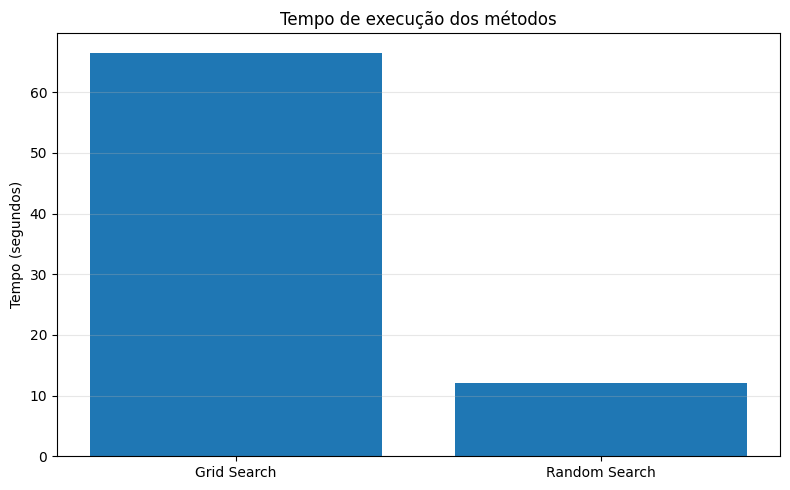

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    ["Grid Search", "Random Search"],
    [tempo_grid, tempo_random]
)

ax.set_title("Tempo de execução dos métodos")
ax.set_ylabel("Tempo (segundos)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Além das métricas numéricas, comparamos as previsões de ambos os métodos com os valores reais de trocas de óleo ao longo do período de teste. Essa visualização ajuda a observar como as previsões acompanham as variações da demanda e se algum método apresenta maior dificuldade em períodos de pico ou de redução nas manutenções.

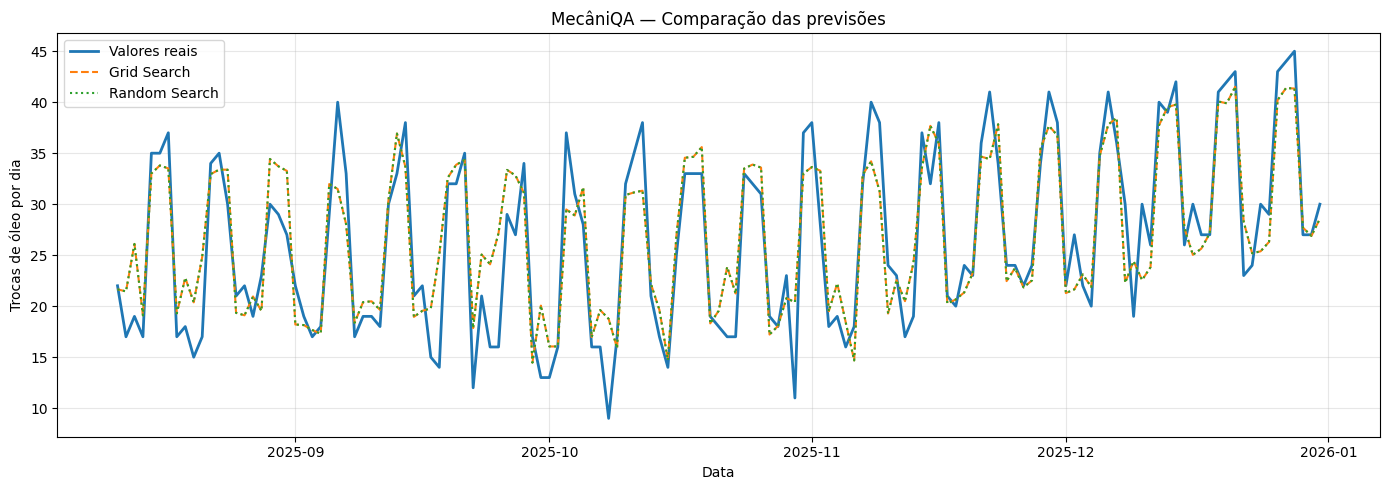

In [10]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_teste.index,
    y_teste,
    label="Valores reais",
    linewidth=2
)

plt.plot(
    y_teste.index,
    pred_grid,
    label="Grid Search",
    linestyle="--"
)

plt.plot(
    y_teste.index,
    pred_random,
    label="Random Search",
    linestyle=":"
)

plt.title("MecâniQA — Comparação das previsões")
plt.xlabel("Data")
plt.ylabel("Trocas de óleo por dia")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Por fim, reunimos os resultados para apoiar a decisão da equipe. A conclusão deve considerar o tempo de execução, o RMSE usado para selecionar os hiperparâmetros e as métricas calculadas no teste final. O Random Search pode ser vantajoso quando economiza tempo e mantém erros competitivos, mas não se deve presumir que ele será sempre mais rápido ou mais preciso.

In [11]:
rmse_grid = resultados.loc[
    "Grid Search", "RMSE (trocas/dia)"
]

rmse_random = resultados.loc[
    "Random Search", "RMSE (trocas/dia)"
]

print("=== CONCLUSÃO DO EXPERIMENTO ===")
print(f"Tempo Grid Search: {tempo_grid:.2f} segundos")
print(f"Tempo Random Search: {tempo_random:.2f} segundos")

if tempo_grid > 0:
    economia = (tempo_grid - tempo_random) / tempo_grid * 100
    print(
        f"Diferença percentual de tempo "
        f"(economia do Random Search): {economia:.1f}%"
    )

if rmse_random < rmse_grid:
    print("O Random Search apresentou menor RMSE no teste.")
elif rmse_grid < rmse_random:
    print("O Grid Search apresentou menor RMSE no teste.")
else:
    print("Os métodos apresentaram RMSE igual no teste.")

print("\nMétricas finais:")
display(resultados.round(3))

=== CONCLUSÃO DO EXPERIMENTO ===
Tempo Grid Search: 66.47 segundos
Tempo Random Search: 12.13 segundos
Diferença percentual de tempo (economia do Random Search): 81.8%
Os métodos apresentaram RMSE igual no teste.

Métricas finais:


,MAE (trocas/dia),RMSE (trocas/dia),MAPE (%),Tempo (segundos)
Grid Search,3.082,3.9,13.941,66.467
Random Search,3.082,3.9,13.941,12.130


Neste experimento, comparamos Grid Search e Random Search para otimizar uma Random Forest destinada à previsão diária de trocas de óleo. O Grid Search avaliou 108 combinações, enquanto o Random Search avaliou 20. A comparação considerou o tempo de execução e as métricas MAE, RMSE e MAPE no mesmo conjunto de teste cronológico. Os resultados mostraram que o método [nome do método] apresentou menor tempo de execução, enquanto o método [nome do método] obteve menor RMSE no teste. Com base nesses resultados, a equipe pode avaliar se a economia de processamento compensa uma eventual diferença na precisão das previsões.